# Ejercicio 04 · Unidad 02 · LAB07
## Clasificador visual con CNN y Model Card

**Estudiante:** Edwing Perez
**Asignatura:** INF-8239 Ciencia de Datos II · Unidad 02
**Repositorio:** https://github.com/edvvdev/unidad02-02
**Manual de la unidad:** U02.LAB07 · Visión computacional: CNN reproducible con Fashion-MNIST

Este notebook recorre el laboratorio completo: **auditoría del dataset** y su reparto
de clases, **partición reproducible**, **curvas de entrenamiento y validación** de los
dos modelos (baseline denso y CNN), **métricas globales y por clase**, **matriz de
confusión**, **errores por clase y ejemplos visuales**, **tabla de costo y tamaño**
y, por último, la **decisión técnica**.

> Todo el código reutilizable vive en `src/inf8239_u02_cv/`. El notebook usa las
> mismas funciones que `scripts/train_cv.py`, de modo que ambos caminos producen
> los mismos artefactos en `reports/`.

In [1]:
import json
import os
import platform
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "src").exists():  # por si nbconvert se ejecuta desde otra carpeta
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from inf8239_u02_cv.data import (
    CLASS_NAMES,
    DEFAULT_SEED,
    DEFAULT_VALIDATION_SIZE,
    NUM_CLASSES,
    audit_dataset,
    class_distribution,
    normalize_images,
    split_train_validation,
)
from inf8239_u02_cv.diagnostico import diagnostico_curvas
from inf8239_u02_cv.experiment import (
    run_budget_study,
    run_experiment,
    set_global_seed,
)
from inf8239_u02_cv.figures import plot_budget_study
from inf8239_u02_cv.models import build_cnn, build_dense

SEED = DEFAULT_SEED
EPOCHS = 8                 # presupuesto que fija el manual (U02.LAB07)
BUDGET_EPOCHS = 25         # estudio complementario de presupuesto
BATCH_SIZE = 128
REPEATS = 3
REPORTS = ROOT / "reports"
MODELS = ROOT / "models"
REPORTS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

os.environ.setdefault("TF_DETERMINISTIC_OPS", "1")
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


def print_table(headers, rows, aligns=None):
    # Imprime una tabla de texto alineada (sin dependencias externas).
    aligns = aligns or ["<"] * len(headers)
    widths = [max(len(str(headers[i])), *(len(str(row[i])) for row in rows))
              for i in range(len(headers))] if rows else [len(str(h)) for h in headers]
    formato = "  ".join("{" + ":" + a + str(w) + "}" for a, w in zip(aligns, widths))
    print(formato.format(*[str(h) for h in headers]))
    print("-" * (sum(widths) + 2 * (len(widths) - 1)))
    for row in rows:
        print(formato.format(*[str(value) for value in row]))


set_global_seed(SEED)
print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("GPU detectada:", tf.config.list_physical_devices("GPU"))
print("Semilla:", SEED, "| Epocas del manual:", EPOCHS, "| Validacion:", DEFAULT_VALIDATION_SIZE)
print("Funcion de auditoria disponible:", audit_dataset.__name__)

I0000 00:00:1793927664.410089  262522 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793927664.410490  262522 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793927664.445935  262522 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793927665.300388  262522 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793927665.300628  262522 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Python: 3.12.15
TensorFlow: 2.21.0
GPU detectada: []
Semilla: 42 | Epocas del manual: 8 | Validacion: 6000
Funcion de auditoria disponible: audit_dataset


E0000 00:00:1793927665.861983  262522 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 1. Auditoría del dataset (antes de entrenar)

Fashion-MNIST es un benchmark público de moda en escala de grises con 28×28 píxeles
y 10 clases. TensorFlow lo descarga a su caché local la primera vez.

Se registran **formas, tipos, rangos de valores y reparto por clase** antes de
entrenar, tal como pide el manual.

In [2]:
(x_train_all, y_train_all), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Entrenamiento oficial:", x_train_all.shape, x_train_all.dtype, "etiquetas:", y_train_all.shape)
print("Prueba oficial:        ", x_test.shape, x_test.dtype, "etiquetas:", y_test.shape)
print("Rango de valores (entrenamiento):", x_train_all.min(), "a", x_train_all.max())
print("Rango de valores (prueba):       ", x_test.min(), "a", x_test.max())
print("Numero de clases:", NUM_CLASSES)
print("Nombres de las clases:", list(CLASS_NAMES))

Entrenamiento oficial: (60000, 28, 28) uint8 etiquetas: (60000,)
Prueba oficial:         (10000, 28, 28) uint8 etiquetas: (10000,)
Rango de valores (entrenamiento): 0 a 255
Rango de valores (prueba):        0 a 255
Numero de clases: 10
Nombres de las clases: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [3]:
distribucion = class_distribution(y_train_all)
print_table(
    ["clase", "entrenamiento (60.000)", "%", "prueba (10.000)", "%"],
    [
        [
            nombre,
            distribucion[nombre],
            f"{100 * distribucion[nombre] / 60000:.2f}",
            class_distribution(y_test)[nombre],
            f"{100 * class_distribution(y_test)[nombre] / 10000:.2f}",
        ]
        for nombre in CLASS_NAMES
    ],
    ["<", ">", ">", ">", ">"],
)
valores = list(distribucion.values())
print("Desbalance del bloque de entrenamiento (max/min):",
      f"{max(valores) / min(valores):.4f}")

clase        entrenamiento (60.000)      %  prueba (10.000)      %
------------------------------------------------------------------
T-shirt/top                    6000  10.00             1000  10.00
Trouser                        6000  10.00             1000  10.00
Pullover                       6000  10.00             1000  10.00
Dress                          6000  10.00             1000  10.00
Coat                           6000  10.00             1000  10.00
Sandal                         6000  10.00             1000  10.00
Shirt                          6000  10.00             1000  10.00
Sneaker                        6000  10.00             1000  10.00
Bag                            6000  10.00             1000  10.00
Ankle boot                     6000  10.00             1000  10.00
Desbalance del bloque de entrenamiento (max/min): 1.0000


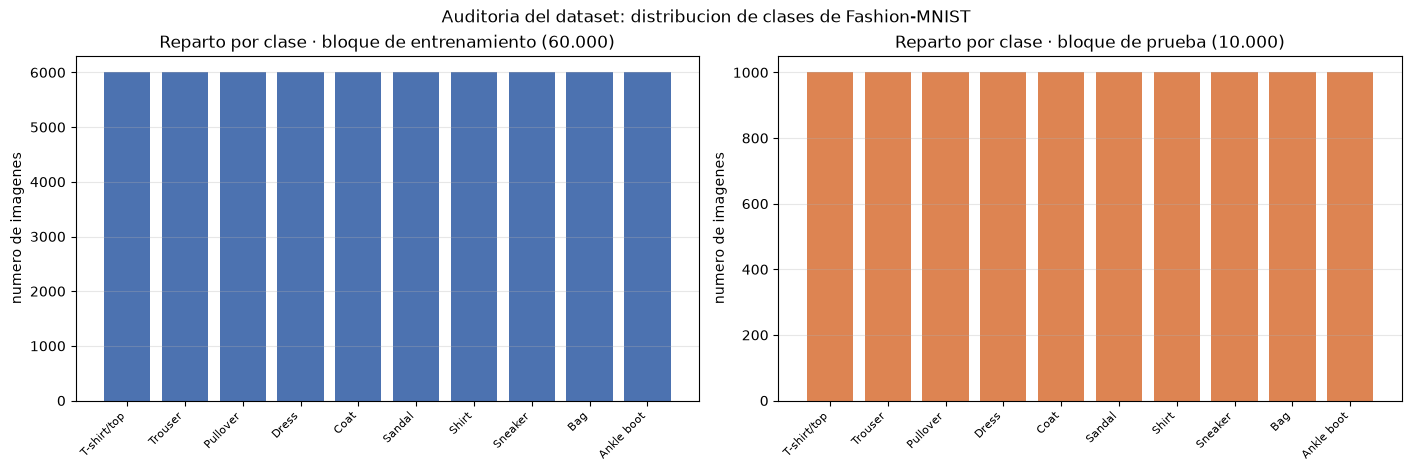

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
posiciones = np.arange(NUM_CLASSES)
conteo_prueba = class_distribution(y_test)
axes[0].bar(posiciones, [distribucion[n] for n in CLASS_NAMES], color="#4C72B0")
axes[0].set_title("Reparto por clase · bloque de entrenamiento (60.000)")
axes[0].set_xticks(posiciones)
axes[0].set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
axes[0].set_ylabel("numero de imagenes")
axes[0].grid(axis="y", alpha=0.3)
axes[1].bar(posiciones, [conteo_prueba[n] for n in CLASS_NAMES], color="#DD8452")
axes[1].set_title("Reparto por clase · bloque de prueba (10.000)")
axes[1].set_xticks(posiciones)
axes[1].set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
axes[1].set_ylabel("numero de imagenes")
axes[1].grid(axis="y", alpha=0.3)
figure.suptitle("Auditoria del dataset: distribucion de clases de Fashion-MNIST")
plt.show()

### 1.1 Normalización y partición reproducible

* Las imágenes se normalizan a `[0, 1]` (float32) y se les añade el canal: `(N, 28, 28, 1)`.
* La partición es **fija y determinista**: de las 60.000 imágenes de entrenamiento,
  las **54.000** primeras forman el conjunto de entrenamiento y las **6.000** últimas
  el de validación. Las **10.000** del bloque oficial de prueba no se usan nunca
  durante el entrenamiento (no hay fuga de datos).
* La semilla es **42** para Python, NumPy y TensorFlow, de modo que el
  inicializador de pesos, el orden de los batches y la elección de ejemplos de
  error son reproducibles.

In [5]:
x_all = normalize_images(x_train_all)
x_test_norm = normalize_images(x_test)
x_train, y_train, x_valid, y_valid = split_train_validation(x_all, y_train_all, DEFAULT_VALIDATION_SIZE)

print("Forma de las imagenes normalizadas:", x_all.shape, x_all.dtype)
print("Rango:", float(x_all.min()), "a", float(x_all.max()))
print()
print("Entrenamiento:", x_train.shape, "| Validacion:", x_valid.shape, "| Prueba:", x_test_norm.shape)
print("La validacion son las ultimas", DEFAULT_VALIDATION_SIZE,
      "filas del bloque de entrenamiento; la prueba nunca se toca al entrenar.")

# Comprobacion de reproducibilidad: dos particiones consecutivas deben ser identicas.
x_train_b, y_train_b, x_valid_b, y_valid_b = split_train_validation(x_all, y_train_all, DEFAULT_VALIDATION_SIZE)
reproducible = (np.array_equal(x_train, x_train_b) and np.array_equal(y_valid, y_valid_b))
print("Particion reproducible:", reproducible)

Forma de las imagenes normalizadas: (60000, 28, 28, 1) float32
Rango: 0.0 a 1.0

Entrenamiento: (54000, 28, 28, 1) | Validacion: (6000, 28, 28, 1) | Prueba: (10000, 28, 28, 1)
La validacion son las ultimas 6000 filas del bloque de entrenamiento; la prueba nunca se toca al entrenar.
Particion reproducible: True


In [6]:
conteo_validacion = class_distribution(y_valid)
print_table(
    ["clase", "entrenamiento", "validacion", "% validacion", "prueba"],
    [
        [
            nombre,
            distribucion[nombre],
            conteo_validacion[nombre],
            f"{100 * conteo_validacion[nombre] / 6000:.2f}",
            conteo_prueba[nombre],
        ]
        for nombre in CLASS_NAMES
    ],
    ["<", ">", ">", ">", ">"],
)
valores_validacion = list(conteo_validacion.values())
print("Reparto de la validacion (minimo - maximo):",
      min(valores_validacion), "-", max(valores_validacion),
      "| desbalance max/min:", f"{max(valores_validacion) / min(valores_validacion):.4f}")

clase        entrenamiento  validacion  % validacion  prueba
------------------------------------------------------------
T-shirt/top           6000         630         10.50    1000
Trouser               6000         584          9.73    1000
Pullover              6000         602         10.03    1000
Dress                 6000         605         10.08    1000
Coat                  6000         633         10.55    1000
Sandal                6000         591          9.85    1000
Shirt                 6000         565          9.42    1000
Sneaker               6000         555          9.25    1000
Bag                   6000         616         10.27    1000
Ankle boot            6000         619         10.32    1000
Reparto de la validacion (minimo - maximo): 555 - 633 | desbalance max/min: 1.1405


## 2. Entrenamiento: baseline denso y CNN con la misma partición

| Modelo | Arquitectura |
|---|---|
| Baseline denso | `Flatten → Dense(64, relu) → Dense(10, softmax)` |
| CNN | `Conv2D(32) → MaxPool → Conv2D(64) → MaxPool → GlobalAveragePooling → Dropout(0.25) → Dense(10, softmax)` |

Los dos modelos se entrenan **con el mismo bloque de 54.000 ejemplos, la misma
validación de 6.000 y la misma semilla**, lo que hace la comparación justa.
Optimizador Adam, pérdida `sparse_categorical_crossentropy`, batch 128 y
`EarlyStopping(patience=2, restore_best_weights=True)`.

La función `run_experiment()` de `src/inf8239_u02_cv/experiment.py` deja las métricas
y las figuras en `reports/`.

In [7]:
# Se guardan las metricas que hubiera escrito el script para poder compararlas despues.
metricas_previas = None
ruta_metricas = REPORTS / "cv_metrics.json"
if ruta_metricas.exists():
    metricas_previas = json.loads(ruta_metricas.read_text(encoding="utf-8"))
    print("Metricas previas detectadas (escritas por scripts/train_cv.py):")
    print(json.dumps(metricas_previas["summary"], indent=2))
else:
    print("Todavia no hay metricas previas: esta ejecucion del notebook sera la primera.")

print()
print("Arquitecturas que se van a entrenar:")
for nombre, constructor in (("Baseline denso", build_dense), ("CNN", build_cnn)):
    modelo = constructor(tf)
    print(f"  {nombre}: {modelo.count_params()} parametros, "
          f"{len(modelo.layers)} capas, salida {modelo.output_shape}")

Metricas previas detectadas (escritas por scripts/train_cv.py):
{
  "dense": {
    "f1_macro": 0.8646890188853495,
    "accuracy": 0.8663,
    "parameters": 50890,
    "model_size_kb": 619.12,
    "train_seconds": 11.821,
    "inference_ms_per_image": 0.0753,
    "epochs_completed": 8
  },
  "cnn": {
    "f1_macro": 0.7891676697708748,
    "accuracy": 0.793,
    "parameters": 19466,
    "model_size_kb": 262.17,
    "train_seconds": 68.011,
    "inference_ms_per_image": 0.0814,
    "epochs_completed": 8
  }
}

Arquitecturas que se van a entrenar:
  Baseline denso: 50890 parametros, 3 capas, salida (None, 10)
  CNN: 19466 parametros, 7 capas, salida (None, 10)


In [8]:
payload = run_experiment(
    epochs=EPOCHS,
    seed=SEED,
    batch_size=BATCH_SIZE,
    repeats=REPEATS,
    reports_dir=REPORTS,
    models_dir=MODELS,
    verbose=2,
)
print("Artefactos en:", REPORTS)

Epoch 1/8


E0000 00:00:1793927667.094172  262522 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


422/422 - 2s - 4ms/step - accuracy: 0.7977 - loss: 0.6009 - val_accuracy: 0.8407 - val_loss: 0.4510


Epoch 2/8


422/422 - 2s - 4ms/step - accuracy: 0.8508 - loss: 0.4320 - val_accuracy: 0.8535 - val_loss: 0.4120


Epoch 3/8


... (28 outputs left out)

422/422 - 8s - 19ms/step - accuracy: 0.7543 - loss: 0.6953 - val_accuracy: 0.7995 - val_loss: 0.5872


E0000 00:00:1793927749.710485  262522 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



=== CNN ===
{
  "f1_macro": 0.7891676697708748,
  "accuracy": 0.793,
  "parameters": 19466,
  "train_seconds": 68.896,
  "inference_ms_per_image": 0.0823,
  "epochs_completed": 8,
  "model_size_kb": 262.17
}



Errores totales de la CNN sobre la prueba: 2070 de 10000
Artefactos escritos en /home/trek/source/uasd/cienciadedatos/tareas/Unidad_2/INF8239_U02_CV/reports
Artefactos en: /home/trek/source/uasd/cienciadedatos/tareas/Unidad_2/INF8239_U02_CV/reports


### 2.1 Curvas de entrenamiento y validación

Se guardan en `reports/training_curves.png`. Los cuatro patrones que propone el
manual se leen así:

| Patrón observado | Lectura |
|---|---|
| Ambas pérdidas disminuyen | El modelo está aprendiendo patrones útiles en ese intervalo. |
| Pérdida de entrenamiento baja y validación sube | Posible sobreajuste: conservar el mejor punto y revisar regularización. |
| Ambas pérdidas permanecen altas | Posible subajuste, configuración inadecuada o problema de datos. |
| Accuracy alta pero una clase con recall bajo | El promedio oculta una debilidad específica: revisar matriz y ejemplos. |

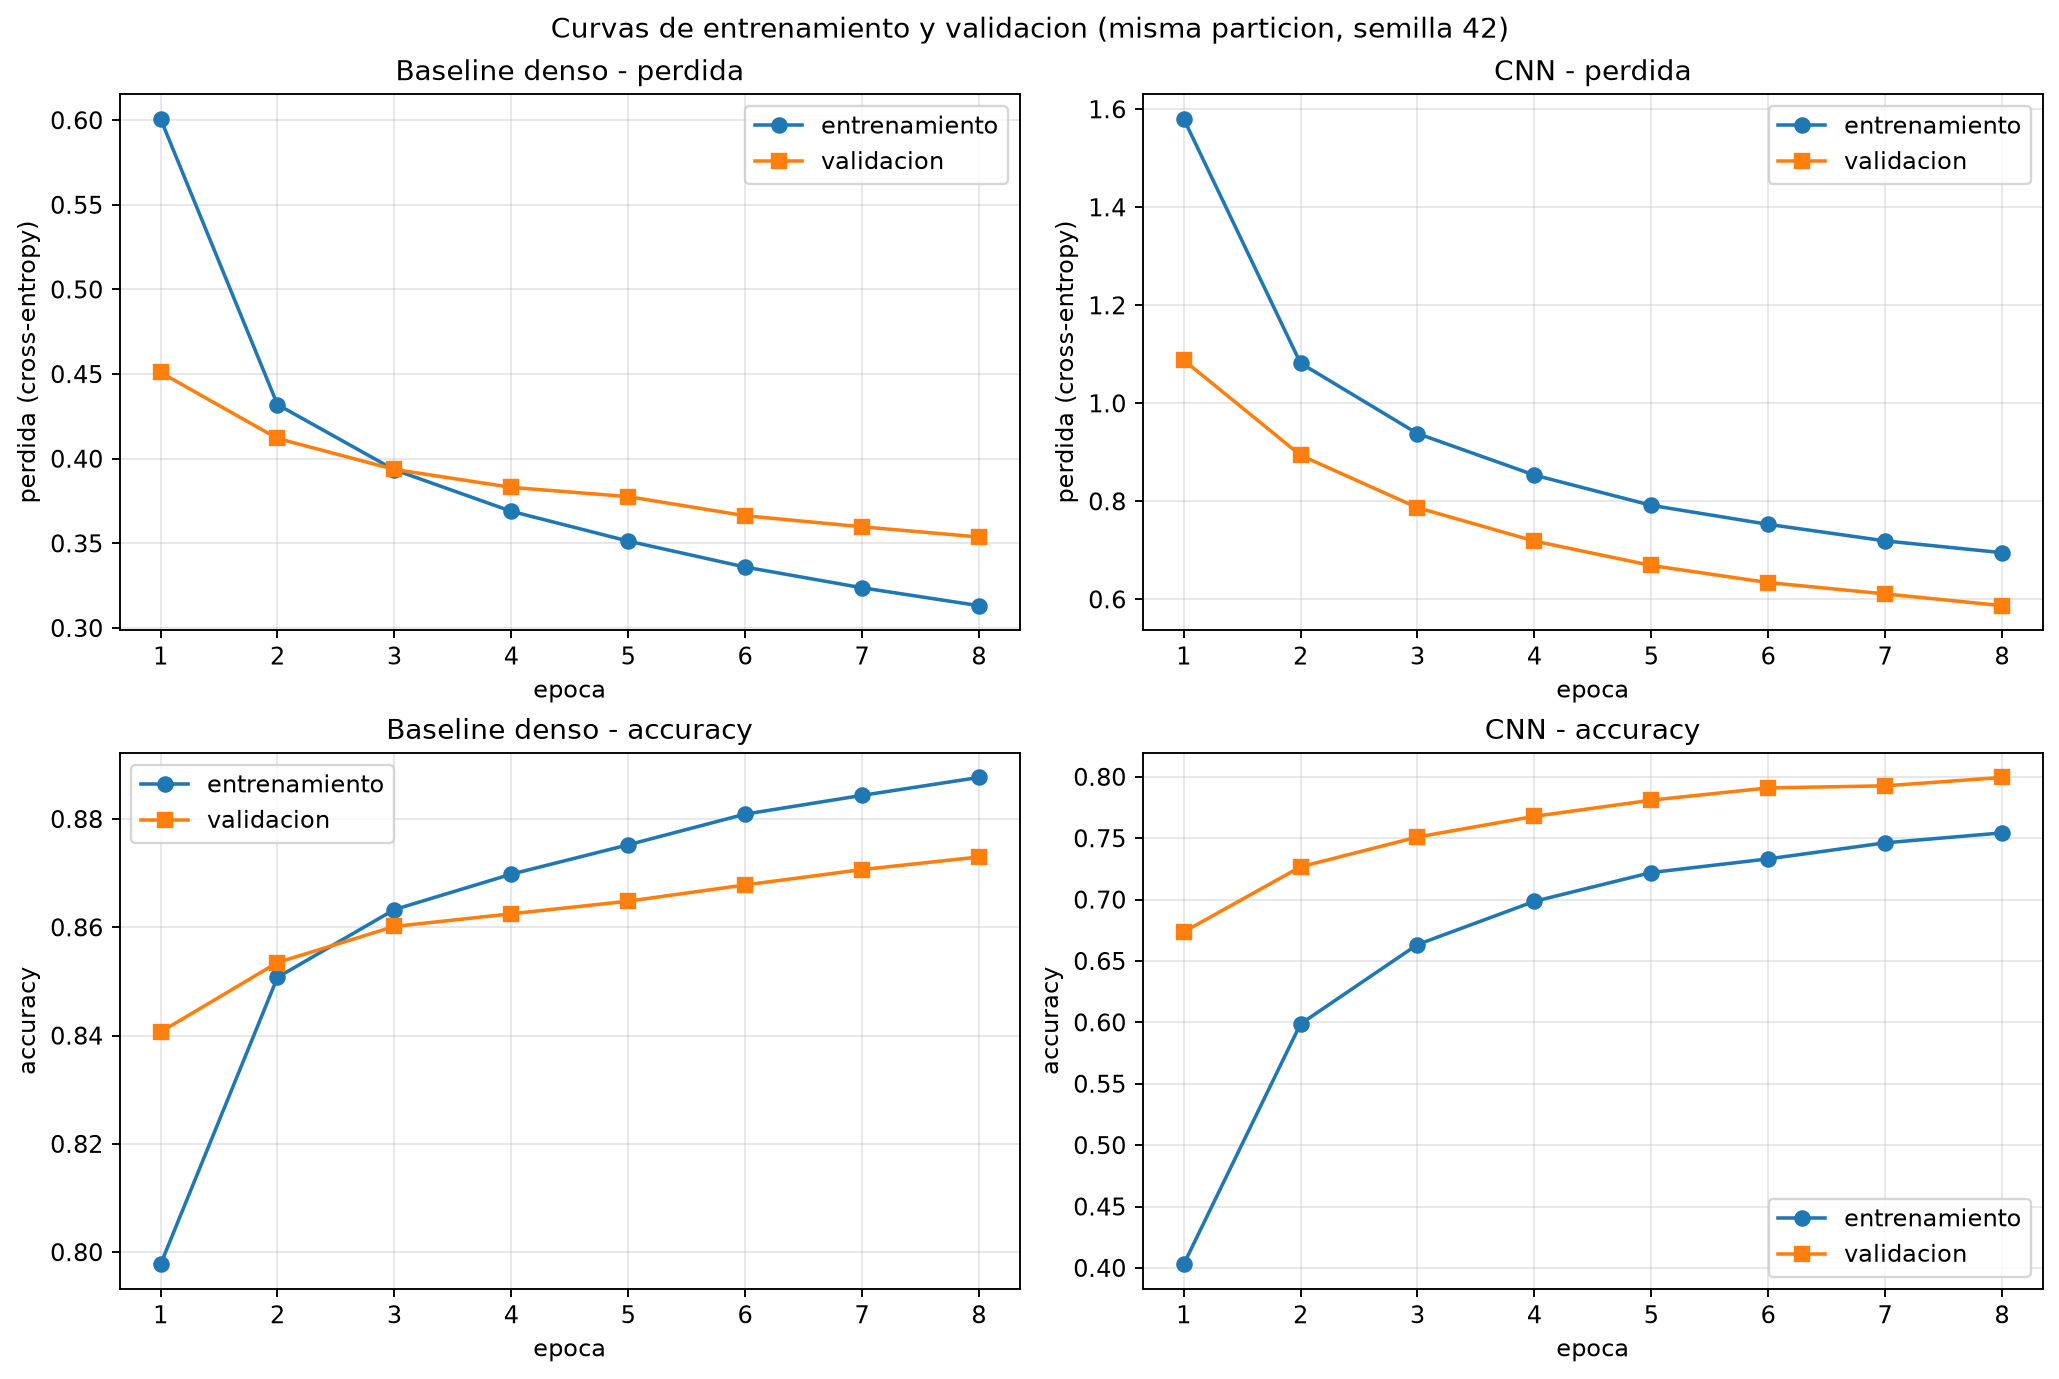

In [9]:
display(Image(filename=str(REPORTS / "training_curves.png"), width=950))

In [10]:
for nombre, titulo in (("dense", "Baseline denso"), ("cnn", "CNN")):
    history = payload[nombre]["history"]
    print(f"--- {titulo} ---")
    print_table(
        ["epoca", "perdida ent.", "perdida val.", "acc. ent.", "acc. val."],
        [
            [
                epoca,
                f"{loss:.4f}",
                f"{val_loss:.4f}",
                f"{acc:.4f}",
                f"{val_acc:.4f}",
            ]
            for epoca, (loss, val_loss, acc, val_acc) in enumerate(
                zip(history["loss"], history["val_loss"],
                    history["accuracy"], history["val_accuracy"]), start=1)
        ],
        [">", ">", ">", ">", ">"],
    )
    print()

# Diagnostico del patron observado (los cuatro patrones del manual).
# Se llama a la MISMA funcion que usan el generador del PDF y
# scripts/verify_cifras.py: src/inf8239_u02_cv/diagnostico.py
for nombre, titulo in (("dense", "Baseline denso"), ("cnn", "CNN")):
    diagnostico = diagnostico_curvas(payload[nombre]["history"])
    print(f"{titulo}: {diagnostico['patron']}")
    print(f"    {diagnostico['frase']}")
    print(f"    caida de la perdida de entrenamiento = {diagnostico['caida_entrenamiento']:.4f} | "
          f"caida de la de validacion = {diagnostico['caida_validacion']:.4f} | "
          f"accuracy de validacion final = {diagnostico['accuracy_validacion_final']:.4f} | "
          f"epocas ejecutadas = {diagnostico['epocas']} de {EPOCHS}")

--- Baseline denso ---
epoca  perdida ent.  perdida val.  acc. ent.  acc. val.
-------------------------------------------------------
    1        0.6009        0.4510     0.7977     0.8407
    2        0.4320        0.4120     0.8508     0.8535
    3        0.3935        0.3937     0.8633     0.8602
    4        0.3690        0.3831     0.8698     0.8625
    5        0.3514        0.3776     0.8752     0.8648
    6        0.3360        0.3663     0.8809     0.8678
    7        0.3238        0.3598     0.8844     0.8707
    8        0.3132        0.3538     0.8877     0.8730

--- CNN ---
epoca  perdida ent.  perdida val.  acc. ent.  acc. val.
-------------------------------------------------------
    1        1.5808        1.0882     0.4029     0.6737
    2        1.0820        0.8940     0.5988     0.7267
    3        0.9384        0.7872     0.6634     0.7510
    4        0.8536        0.7190     0.6986     0.7678
    5        0.7919        0.6692     0.7221     0.7810
    6       

## 3. Métricas globales: denso frente a CNN

La comparación usa **la misma partición** y la misma semilla, y el tiempo de
inferencia es la **mediana de tres mediciones** sobre las 10.000 imágenes de prueba.

In [11]:
filas_global = [
    [
        "Baseline denso",
        f"{payload['dense']['f1_macro']:.4f}",
        f"{payload['dense']['accuracy']:.4f}",
        payload["dense"]["parameters"],
        f"{payload['dense']['model_size_kb']:.2f}",
        f"{payload['dense']['train_seconds']:.1f}",
        f"{payload['dense']['inference_ms_per_image']:.4f}",
        payload["dense"]["epochs_completed"],
    ],
    [
        "CNN",
        f"{payload['cnn']['f1_macro']:.4f}",
        f"{payload['cnn']['accuracy']:.4f}",
        payload["cnn"]["parameters"],
        f"{payload['cnn']['model_size_kb']:.2f}",
        f"{payload['cnn']['train_seconds']:.1f}",
        f"{payload['cnn']['inference_ms_per_image']:.4f}",
        payload["cnn"]["epochs_completed"],
    ],
]
encabezados = ["modelo", "F1 macro", "accuracy", "parametros", "tamano (KB)",
               "entrenamiento (s)", "inferencia mediana (ms/img)", "epocas"]
print_table(encabezados, filas_global, ["<", ">", ">", ">", ">", ">", ">", ">"])
print()
print("Mediciones de inferencia (ms por imagen) y mediana usada:")
print("  denso:", payload["dense"]["inference_ms_per_image_runs"],
      "-> mediana", payload["dense"]["inference_ms_per_image"])
print("  CNN  :", payload["cnn"]["inference_ms_per_image_runs"],
      "-> mediana", payload["cnn"]["inference_ms_per_image"])
print()
print("Hardware y entorno de ejecucion:")
for clave, valor in payload["meta"]["hardware"].items():
    print(f"  {clave}: {valor}")

modelo          F1 macro  accuracy  parametros  tamano (KB)  entrenamiento (s)  inferencia mediana (ms/img)  epocas
-------------------------------------------------------------------------------------------------------------------
Baseline denso    0.8647    0.8663       50890       619.12               12.2                       0.0512       8
CNN               0.7892    0.7930       19466       262.17               68.9                       0.0823       8

Mediciones de inferencia (ms por imagen) y mediana usada:
  denso: [0.0512, 0.0446, 0.0622] -> mediana 0.0512
  CNN  : [0.0946, 0.0786, 0.0823] -> mediana 0.0823

Hardware y entorno de ejecucion:
  platform: Linux-6.12.113+deb13-amd64-x86_64-with-glibc2.41
  processor: x86_64
  python: 3.12.15
  tensorflow: 2.21.0
  numpy: 2.5.3
  cpu_count: 20
  gpu_devices: []


## 4. Métricas por clase

El promedio global puede esconder una debilidad. La tabla siguiente viene de
`reports/cv_per_class.csv` (classification report por clase).

In [12]:
import csv

with (REPORTS / "cv_per_class.csv").open(encoding="utf-8") as archivo:
    filas_pc = list(csv.DictReader(archivo))

for modelo in ("dense", "cnn"):
    print(f"--- {modelo} ---")
    print_table(
        ["clase", "precision", "recall", "F1", "soporte"],
        [
            [
                fila["class_name"],
                fila["precision"],
                fila["recall"],
                fila["f1"],
                fila["support"],
            ]
            for fila in filas_pc if fila["model"] == modelo
        ],
        ["<", ">", ">", ">", ">"],
    )
    print()

--- dense ---
clase        precision  recall      F1  soporte
-----------------------------------------------
T-shirt/top      0.791   0.848  0.8185     1000
Trouser         0.9818   0.969  0.9753     1000
Pullover        0.8362   0.684  0.7525     1000
Dress           0.8369   0.903  0.8687     1000
Coat            0.7108    0.87  0.7824     1000
Sandal          0.9349   0.962  0.9483     1000
Shirt           0.7193   0.597  0.6525     1000
Sneaker         0.9289    0.94  0.9344     1000
Bag             0.9724   0.953  0.9626     1000
Ankle boot       0.967   0.937  0.9518     1000

--- cnn ---
clase        precision  recall      F1  soporte
-----------------------------------------------
T-shirt/top     0.6446   0.807  0.7167     1000
Trouser         0.9883   0.932  0.9593     1000
Pullover        0.7064    0.64  0.6716     1000
Dress           0.7542   0.844  0.7966     1000
Coat              0.66   0.664   0.662     1000
Sandal          0.9506   0.885  0.9166     1000
Shirt        

In [13]:
print("Classification report de la CNN (salida de sklearn):")
print(payload["cnn"]["classification_report"])
print("Classification report del baseline denso:")
print(payload["dense"]["classification_report"])

Classification report de la CNN (salida de sklearn):
              precision    recall  f1-score   support

 T-shirt/top     0.6446    0.8070    0.7167      1000
     Trouser     0.9883    0.9320    0.9593      1000
    Pullover     0.7064    0.6400    0.6716      1000
       Dress     0.7542    0.8440    0.7966      1000
        Coat     0.6600    0.6640    0.6620      1000
      Sandal     0.9506    0.8850    0.9166      1000
       Shirt     0.4973    0.3720    0.4256      1000
     Sneaker     0.8547    0.9530    0.9012      1000
         Bag     0.9168    0.9370    0.9268      1000
  Ankle boot     0.9353    0.8960    0.9152      1000

    accuracy                         0.7930     10000
   macro avg     0.7908    0.7930    0.7892     10000
weighted avg     0.7908    0.7930    0.7892     10000

Classification report del baseline denso:
              precision    recall  f1-score   support

 T-shirt/top     0.7910    0.8480    0.8185      1000
     Trouser     0.9818    0.9690    

## 5. Matriz de confusión

`reports/confusion_cnn.png` (y `reports/confusion_dense.png` para el baseline).
Las filas son la clase real y las columnas la clase predicha.

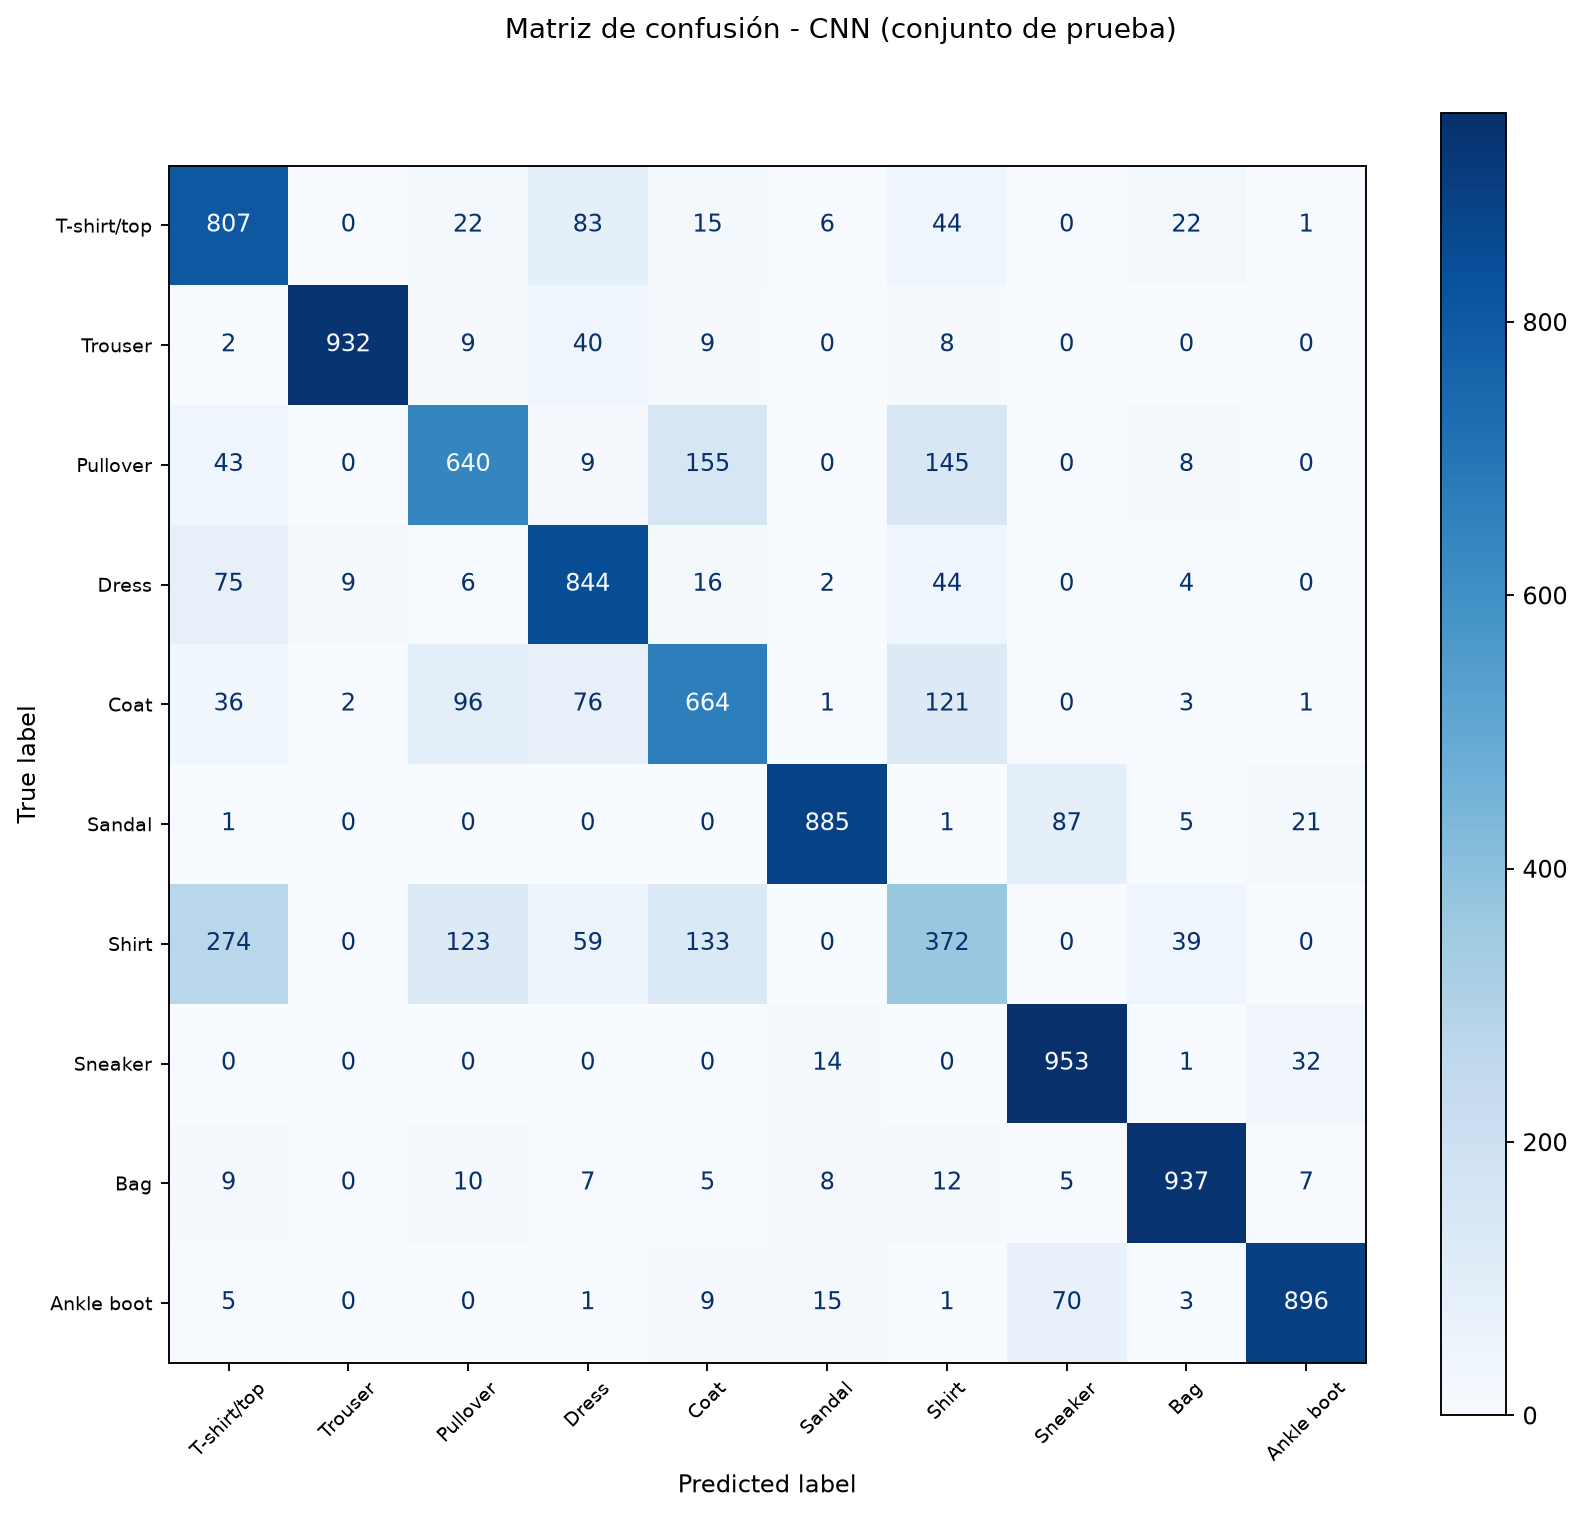

Suma de la diagonal (aciertos de la CNN): 7930
Suma de la matriz (ejemplos de prueba): 10000
Los errores por clase se derivan de esta matriz en el apartado 6.


In [14]:
display(Image(filename=str(REPORTS / "confusion_cnn.png"), width=820))
confusion = np.array(payload["cnn"]["confusion_matrix"])
print("Suma de la diagonal (aciertos de la CNN):", int(np.trace(confusion)))
print("Suma de la matriz (ejemplos de prueba):", int(confusion.sum()))
print("Los errores por clase se derivan de esta matriz en el apartado 6.")

## 6. Errores por clase y ejemplos visuales

* `reports/cv_errors_by_class.csv`: errores, falsos positivos y recall por clase.
* `reports/errors_by_class.png`: recall y número de errores por clase.
* `reports/cnn_errors.png`: 16 ejemplos mal clasificados **elegidos al azar con
  semilla fija** (42), con su clase real y su predicción.
* `reports/cnn_error_samples.csv`: ficha de esos 16 ejemplos con la confianza.

In [15]:
with (REPORTS / "cv_errors_by_class.csv").open(encoding="utf-8") as archivo:
    filas_err = list(csv.DictReader(archivo))

for modelo in ("dense", "cnn"):
    print(f"--- {modelo} ---")
    print_table(
        ["clase", "soporte", "aciertos", "errores", "tasa error", "recall", "falsos pos."],
        [
            [
                fila["class_name"],
                fila["support"],
                fila["correct"],
                fila["errors"],
                fila["error_rate"],
                fila["recall"],
                fila["false_positives"],
            ]
            for fila in filas_err if fila["model"] == modelo
        ],
        ["<", ">", ">", ">", ">", ">", ">"],
    )
    print()

--- dense ---
clase        soporte  aciertos  errores  tasa error  recall  falsos pos.
------------------------------------------------------------------------
T-shirt/top     1000       848      152       0.152   0.848          224
Trouser         1000       969       31       0.031   0.969           18
Pullover        1000       684      316       0.316   0.684          134
Dress           1000       903       97       0.097   0.903          176
Coat            1000       870      130        0.13    0.87          354
Sandal          1000       962       38       0.038   0.962           67
Shirt           1000       597      403       0.403   0.597          233
Sneaker         1000       940       60        0.06    0.94           72
Bag             1000       953       47       0.047   0.953           27
Ankle boot      1000       937       63       0.063   0.937           32

--- cnn ---
clase        soporte  aciertos  errores  tasa error  recall  falsos pos.
------------------------

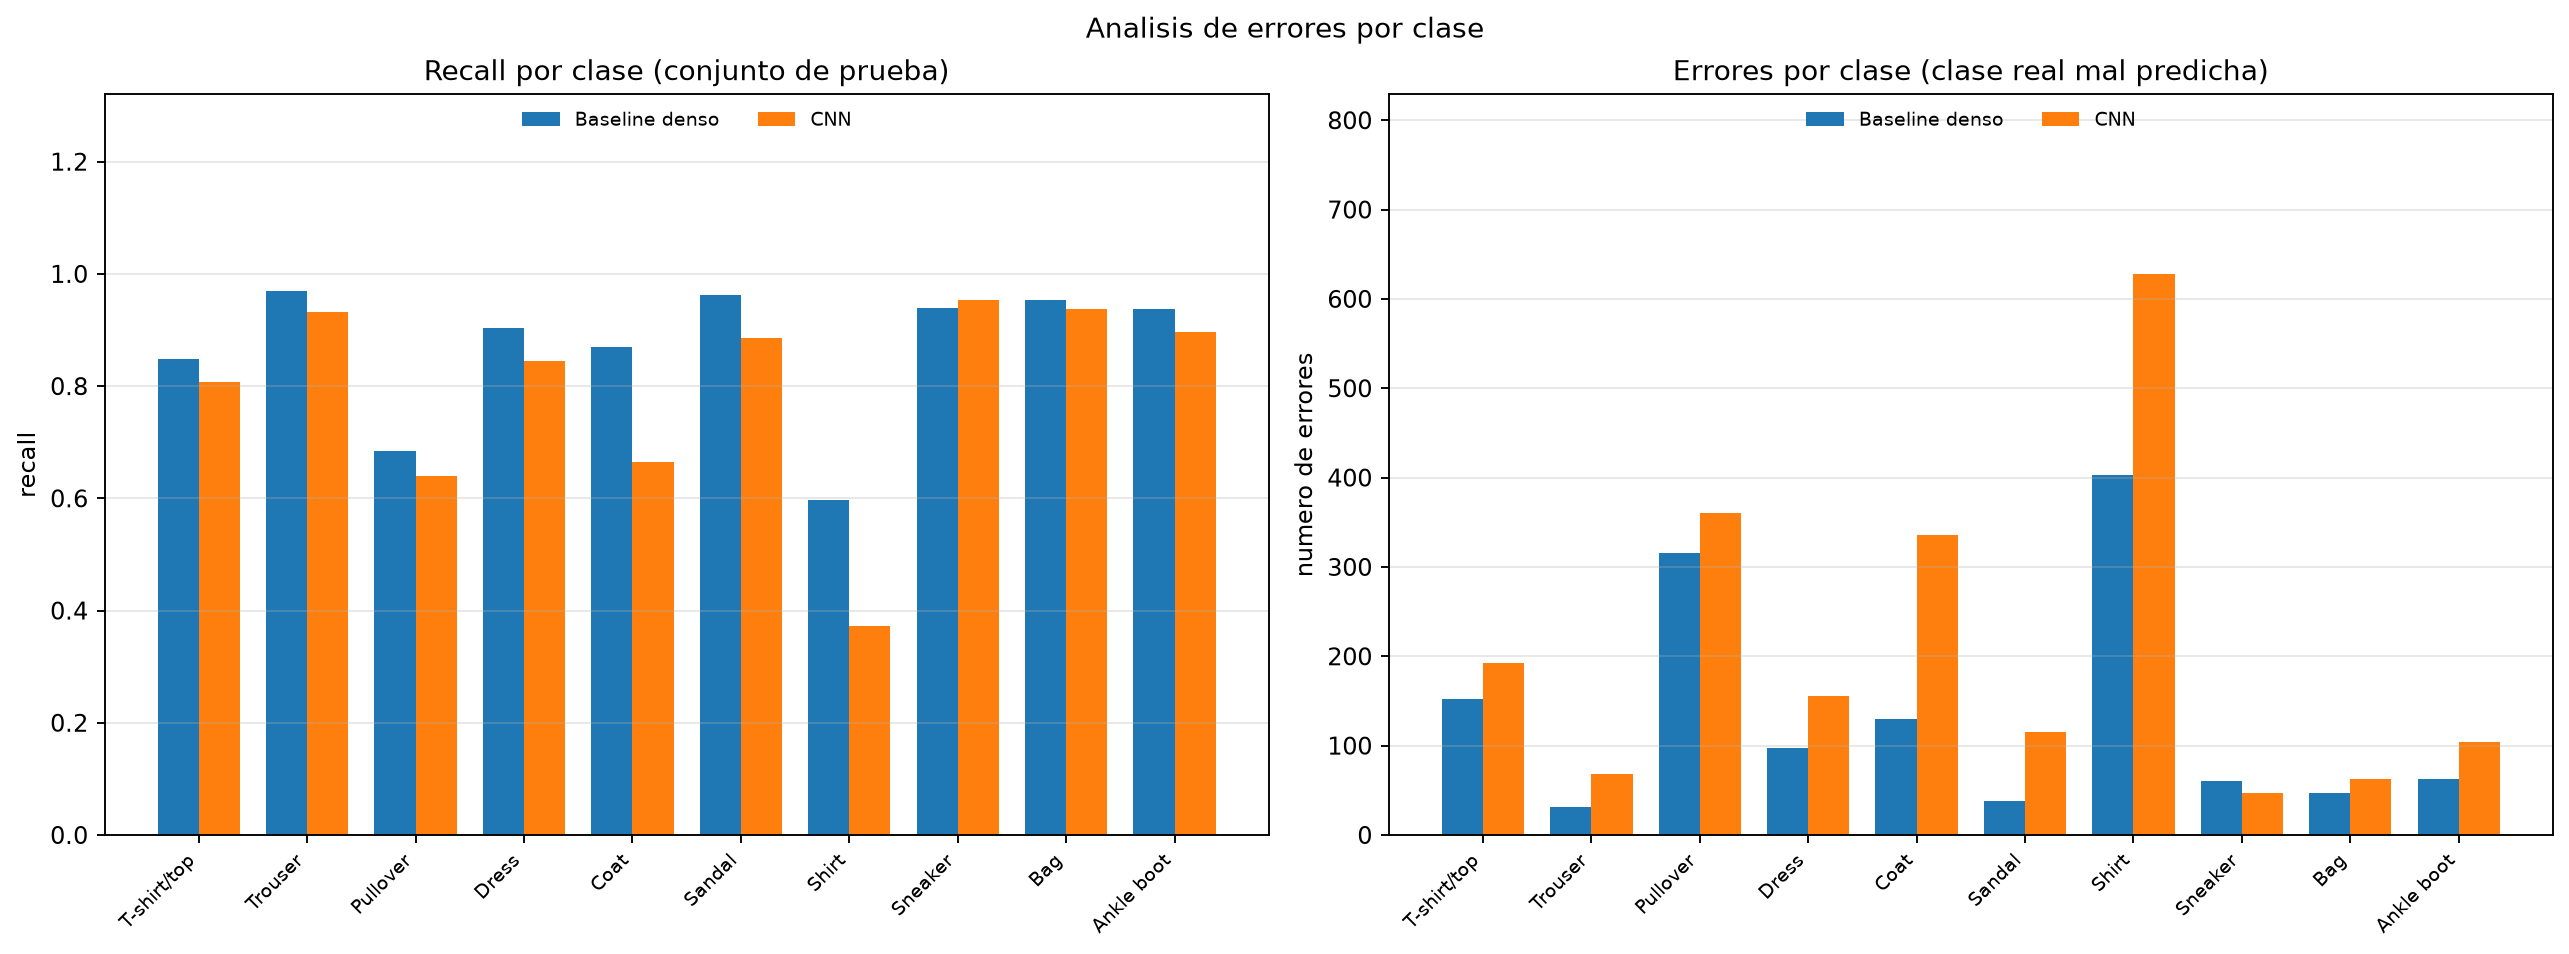

In [16]:
display(Image(filename=str(REPORTS / "errors_by_class.png"), width=950))

In [17]:
for modelo in ("dense", "cnn"):
    propias = [fila for fila in filas_err if fila["model"] == modelo]
    propias_ordenadas = sorted(propias, key=lambda fila: float(fila["recall"]))
    print(f"Clases que el modelo {modelo} pierde (ordenadas por recall mas bajo):")
    for fila in propias_ordenadas:
        print(f"  {fila['class_name']:<12} recall={float(fila['recall']):.3f} | "
              f"errores={fila['errors']:>4} de {fila['support']} | "
              f"falsos positivos={fila['false_positives']:>4}")
    print(f"  Total de errores sobre 10.000 ejemplos: "
          f"{sum(int(f['errors']) for f in propias)}")
    print()

Clases que el modelo dense pierde (ordenadas por recall mas bajo):
  Shirt        recall=0.597 | errores= 403 de 1000 | falsos positivos= 233
  Pullover     recall=0.684 | errores= 316 de 1000 | falsos positivos= 134
  T-shirt/top  recall=0.848 | errores= 152 de 1000 | falsos positivos= 224
  Coat         recall=0.870 | errores= 130 de 1000 | falsos positivos= 354
  Dress        recall=0.903 | errores=  97 de 1000 | falsos positivos= 176
  Ankle boot   recall=0.937 | errores=  63 de 1000 | falsos positivos=  32
  Sneaker      recall=0.940 | errores=  60 de 1000 | falsos positivos=  72
  Bag          recall=0.953 | errores=  47 de 1000 | falsos positivos=  27
  Sandal       recall=0.962 | errores=  38 de 1000 | falsos positivos=  67
  Trouser      recall=0.969 | errores=  31 de 1000 | falsos positivos=  18
  Total de errores sobre 10.000 ejemplos: 1337

Clases que el modelo cnn pierde (ordenadas por recall mas bajo):
  Shirt        recall=0.372 | errores= 628 de 1000 | falsos positivos=

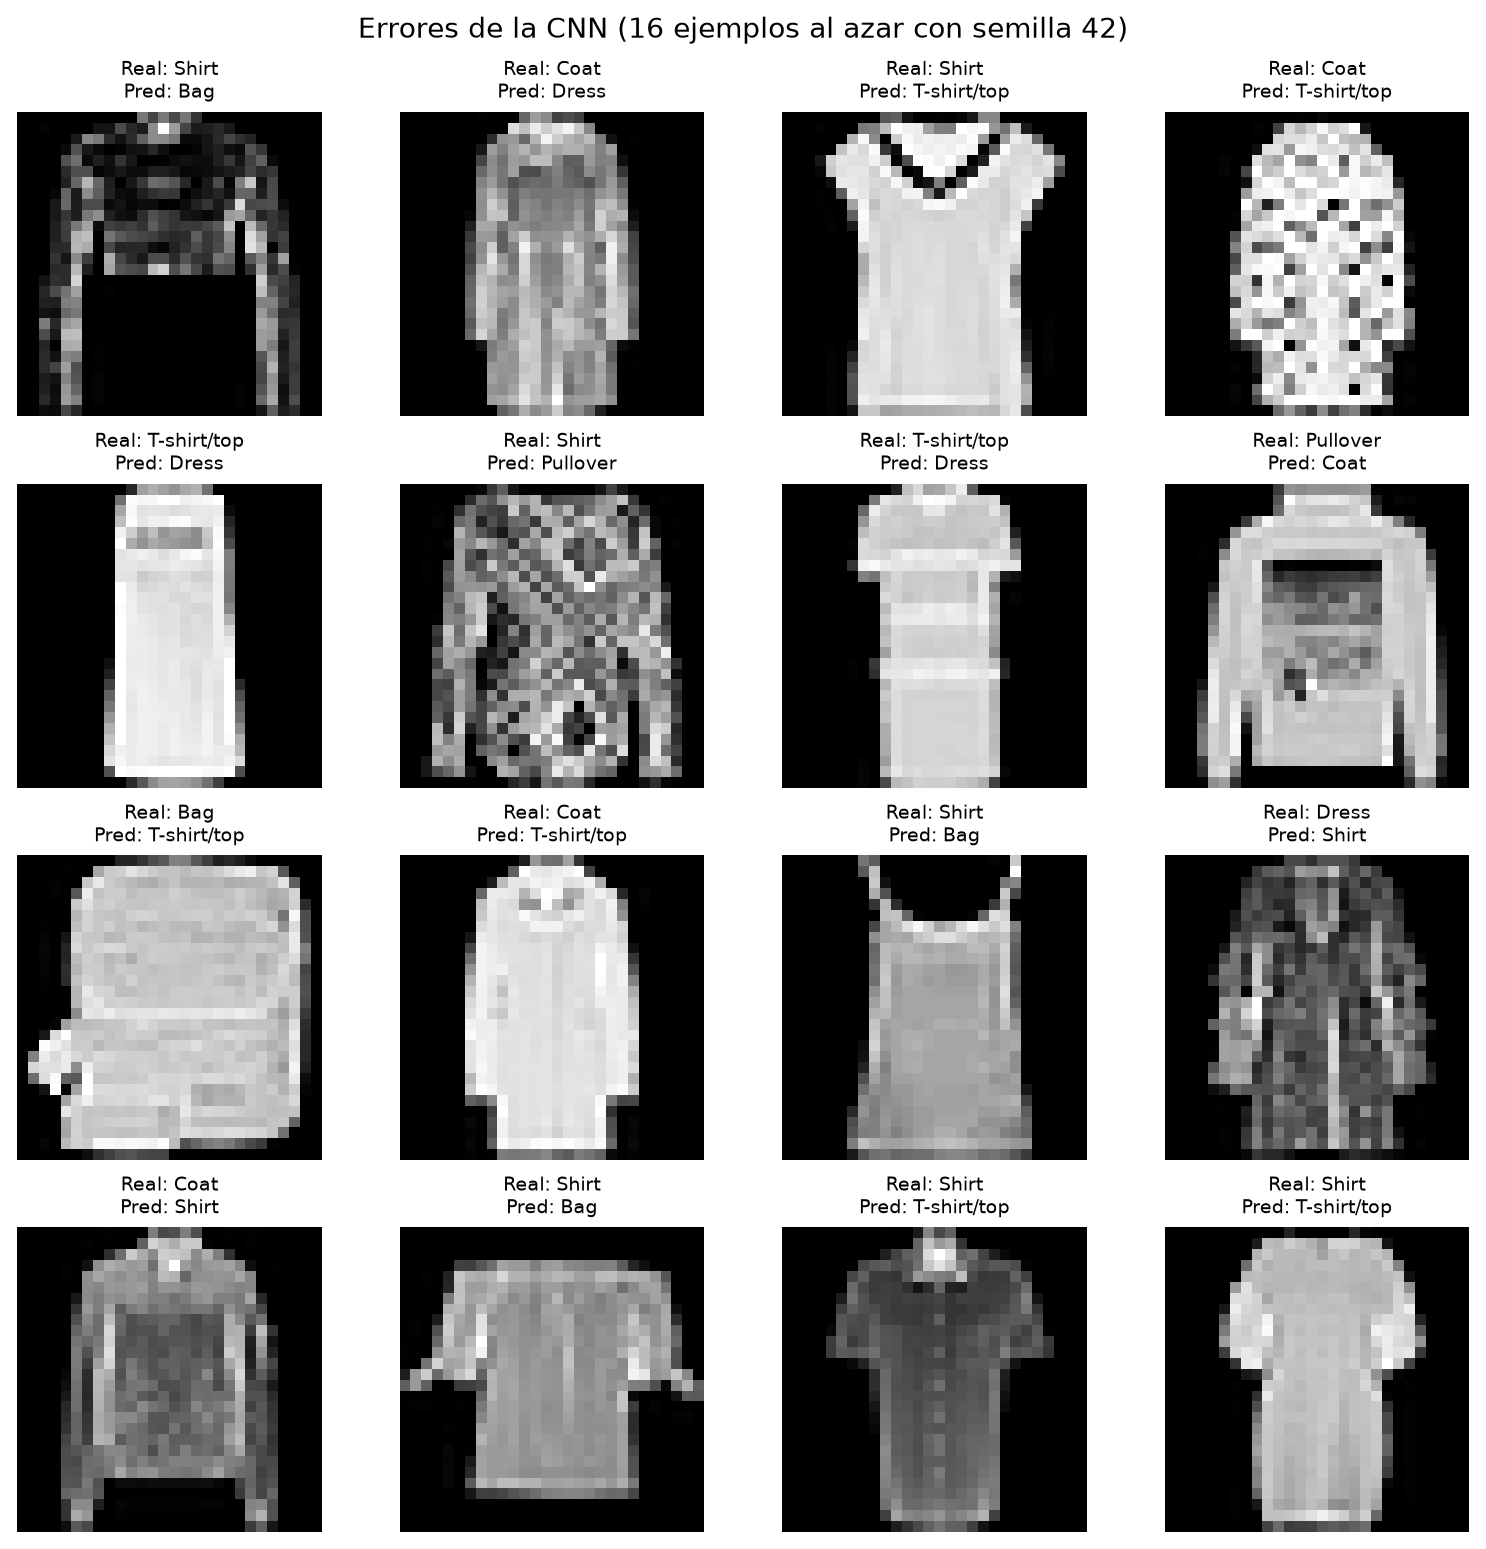

indice  clase real   clase predicha  confianza  prob. real
----------------------------------------------------------
   909  Shirt        Bag                0.3407      0.1894
   939  Coat         Dress               0.446       0.158
   977  Shirt        T-shirt/top        0.6484      0.1947
  2062  Coat         T-shirt/top        0.2896      0.2645
  4262  T-shirt/top  Dress              0.8344        0.08
  4337  Shirt        Pullover           0.3968       0.384
  5334  T-shirt/top  Dress              0.7756      0.1643
  6511  Pullover     Coat               0.5253      0.2725
  6966  Bag          T-shirt/top         0.315      0.1362
  7154  Coat         T-shirt/top        0.3504      0.3091
  7334  Shirt        Bag                0.5195      0.1792
  7646  Dress        Shirt              0.3784      0.1245
  7751  Coat         Shirt               0.379       0.343
  7910  Shirt        Bag                0.4948       0.138
  8597  Shirt        T-shirt/top        0.5086      0.16

In [18]:
display(Image(filename=str(REPORTS / "cnn_errors.png"), width=820))

with (REPORTS / "cnn_error_samples.csv").open(encoding="utf-8") as archivo:
    print_table(
        ["indice", "clase real", "clase predicha", "confianza", "prob. real"],
        [
            [
                fila["test_index"],
                fila["true_class"],
                fila["predicted_class"],
                fila["confidence"],
                fila["true_probability"],
            ]
            for fila in csv.DictReader(archivo)
        ],
        [">", "<", "<", ">", ">"],
    )

### 6.1 Lectura de los errores

Los pares que se repiten son los esperados en un benchmark de moda en 28×28:

* **Shirt ↔ T-shirt/top ↔ Pullover ↔ Coat**: las prendas de torso se distinguen por
  un cuello y una manga de pocos píxeles; cuando el cuello está abierto o la manga
  no se distingue, la imagen es genuinamente ambigua.
* **Sandal ↔ Sneaker ↔ Ankle boot**: el calzado se separa por la suela y el tobillo,
  detalles que ocupan muy pocos píxeles en la parte inferior de la imagen.
* **T-shirt/top ↔ Dress**: la diferencia es la longitud y la forma; cuando la prenda
  ocupa todo el marco, ambas clases se solapan.

En ninguna de estas parejas hay un "fallo humano" evidente: son ambigüedades de la
misma imagen. Esto **no demuestra preparación para imágenes médicas, OCR ni
vigilancia**: Fashion-MNIST es un benchmark didáctico de siluetas de moda.

## 7. Estudio de presupuesto de entrenamiento (complemento)

El experimento principal usa el presupuesto que fija el manual (8 épocas). Las
curvas dejan una pregunta abierta: **¿la diferencia entre los dos modelos es una
limitación de la arquitectura o del número de épocas?**

Este apartado repite el experimento con **25 épocas** para los dos modelos, con la
**misma partición y la misma semilla**. Las curvas por época se calculan sobre el
conjunto de **validación**, nunca sobre la prueba, para no filtrar información.
Es un experimento **complementario**: la comparación oficial sigue siendo la de 8
épocas, y su resultado se reporta sin modificar.

Se reutiliza reports/budget_study.json, generado por scripts/budget_study.py
con la misma particion y la misma semilla.


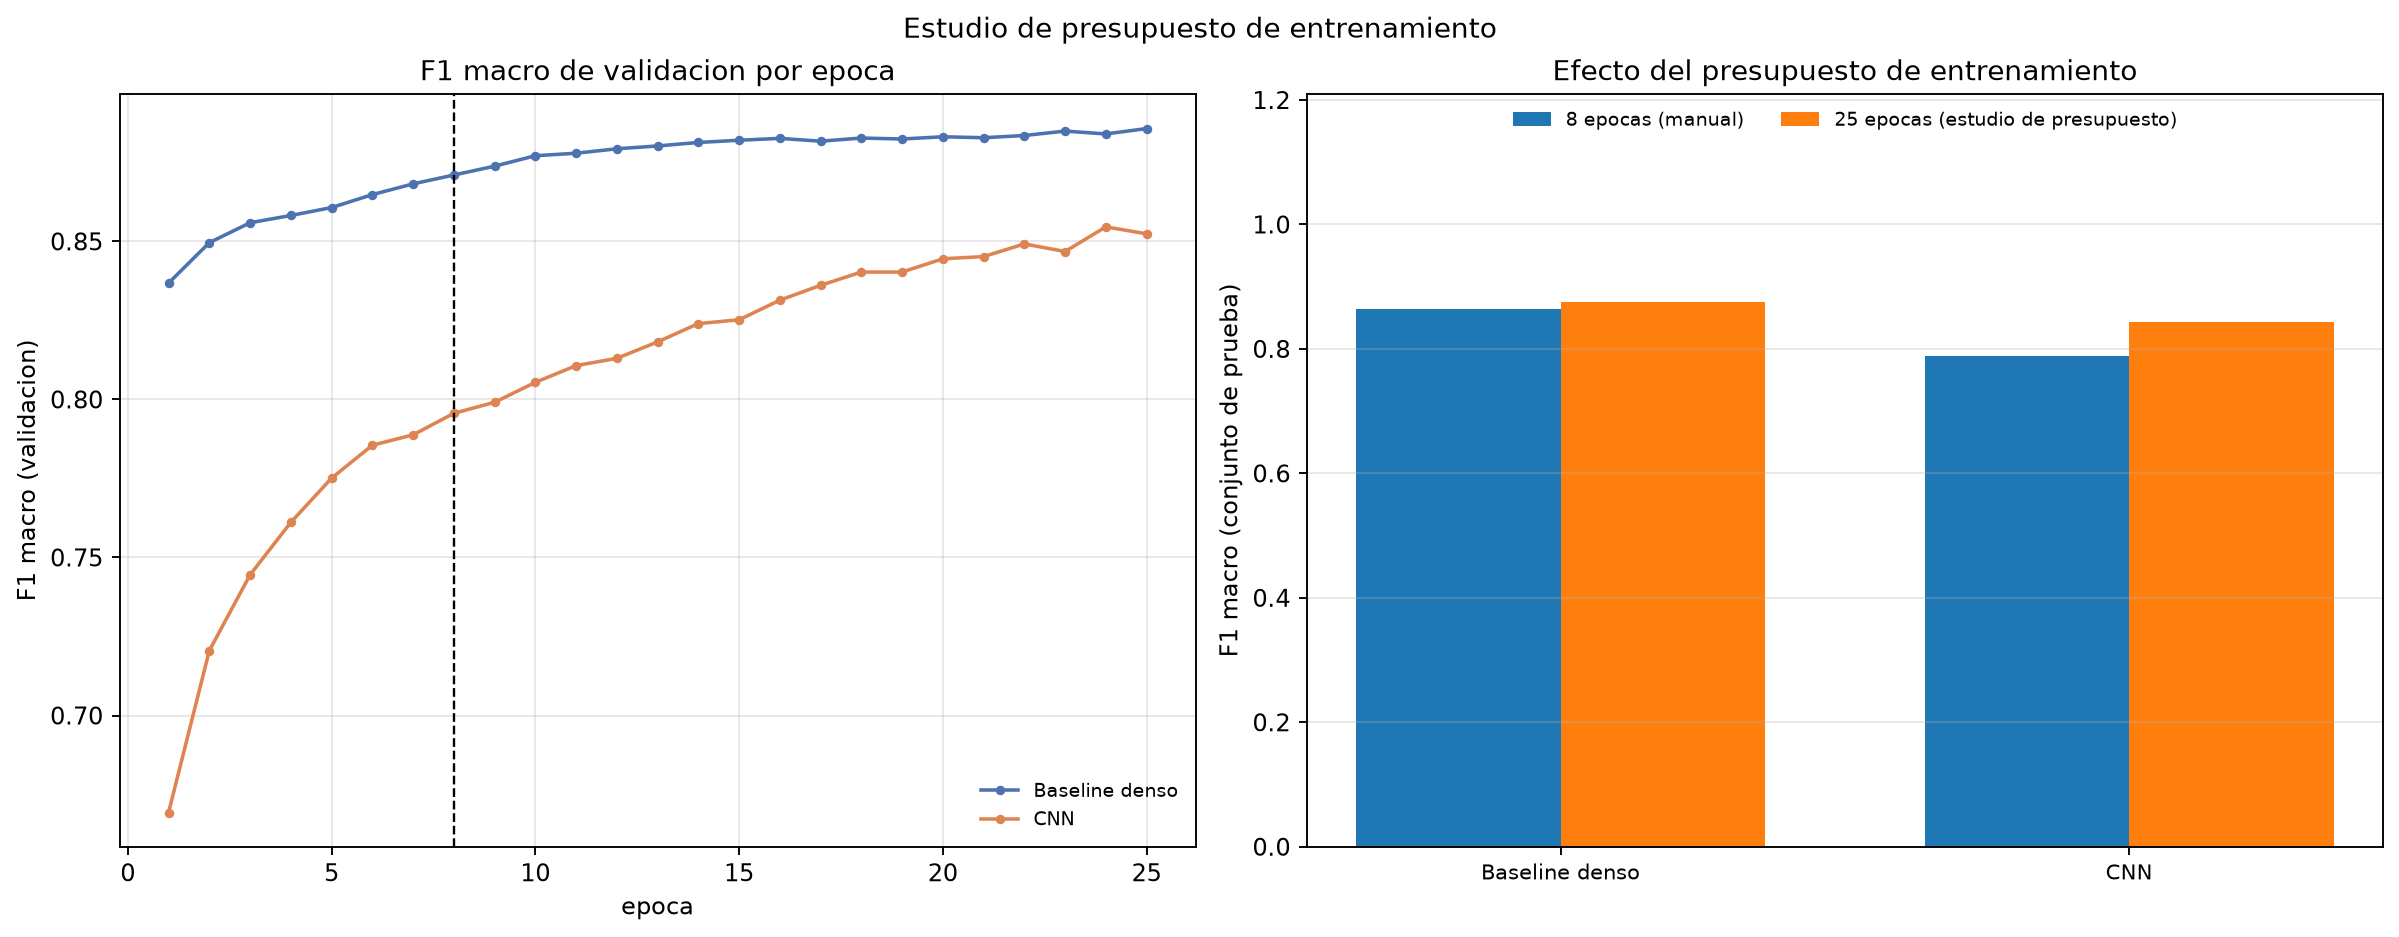

In [19]:
ruta_estudio = REPORTS / "budget_study.json"
estudio = None
if ruta_estudio.exists():
    previo = json.loads(ruta_estudio.read_text(encoding="utf-8"))
    if previo["meta"]["epochs"] == BUDGET_EPOCHS and previo["meta"]["seed"] == SEED:
        estudio = previo
        print("Se reutiliza reports/budget_study.json, generado por scripts/budget_study.py")
        print("con la misma particion y la misma semilla.")
if estudio is None:
    print("No hay estudio de presupuesto previo: se ejecuta ahora en el notebook.")
    estudio = run_budget_study(
        epochs=BUDGET_EPOCHS,
        seed=SEED,
        batch_size=BATCH_SIZE,
        reports_dir=REPORTS,
        models_dir=MODELS,
        verbose=2,
    )

linea_base = (
    {nombre: metricas_previas[nombre]["f1_macro"] for nombre in ("dense", "cnn")}
    if metricas_previas is not None
    else {nombre: payload[nombre]["f1_macro"] for nombre in ("dense", "cnn")}
)
plot_budget_study(estudio, linea_base, REPORTS / "budget_study.png", prescribed_epochs=EPOCHS)
display(Image(filename=str(REPORTS / "budget_study.png"), width=950))

In [20]:
print_table(
    ["modelo", "F1 macro 8 ep.", "F1 macro 25 ep.", "parametros", "tamano (KB)",
     "entrenamiento 8 ep. (s)", "entrenamiento 25 ep. (s)"],
    [
        [
            nombre,
            f"{payload[nombre]['f1_macro']:.4f}",
            f"{estudio['models'][nombre]['f1_macro_test']:.4f}",
            payload[nombre]["parameters"],
            f"{payload[nombre]['model_size_kb']:.2f}",
            f"{payload[nombre]['train_seconds']:.1f}",
            f"{estudio['models'][nombre]['train_seconds']:.1f}",
        ]
        for nombre in ("dense", "cnn")
    ],
    ["<", ">", ">", ">", ">", ">", ">"],
)

modelo  F1 macro 8 ep.  F1 macro 25 ep.  parametros  tamano (KB)  entrenamiento 8 ep. (s)  entrenamiento 25 ep. (s)
-------------------------------------------------------------------------------------------------------------------
dense           0.8647           0.8761       50890       619.12                     12.2                      32.0
cnn             0.7892           0.8439       19466       262.17                     68.9                     215.3


## 8. Costo, tamaño y lectura Green AI

El manual es explícito: *más accuracy no es automáticamente mejor*. Se comparan
desempeño, parámetros, tamaño en disco, tiempo de entrenamiento, tiempo de
inferencia y hardware.

In [21]:
dens = payload["dense"]
cnn = payload["cnn"]
print("Comparacion de costo con el presupuesto del manual (8 epocas):")
print(f"  F1 macro:            denso {dens['f1_macro']:.4f} | CNN {cnn['f1_macro']:.4f} "
      f"({cnn['f1_macro'] - dens['f1_macro']:+.4f})")
print(f"  Parametros:          denso {dens['parameters']} | CNN {cnn['parameters']} "
      f"({cnn['parameters'] - dens['parameters']:+d})")
print(f"  Tamano del archivo:  denso {dens['model_size_kb']:.2f} KB | CNN {cnn['model_size_kb']:.2f} KB "
      f"({cnn['model_size_kb'] - dens['model_size_kb']:+.2f} KB)")
print(f"  Entrenamiento:        denso {dens['train_seconds']:.1f} s | CNN {cnn['train_seconds']:.1f} s "
      f"({cnn['train_seconds'] - dens['train_seconds']:+.1f} s)")
print(f"  Inferencia mediana:  denso {dens['inference_ms_per_image']:.4f} ms/img | "
      f"CNN {cnn['inference_ms_per_image']:.4f} ms/img "
      f"({cnn['inference_ms_per_image'] - dens['inference_ms_per_image']:+.4f} ms/img)")
print()
print("Costo con el presupuesto ampliado (25 epocas, estudio complementario):")
for nombre in ("dense", "cnn"):
    modelo = estudio["models"][nombre]
    print(f"  {nombre}: F1 macro {modelo['f1_macro_test']:.4f} | "
          f"{modelo['train_seconds']:.1f} s de entrenamiento | "
          f"{modelo['parameters']} parametros | {modelo['model_size_kb']:.2f} KB")

Comparacion de costo con el presupuesto del manual (8 epocas):
  F1 macro:            denso 0.8647 | CNN 0.7892 (-0.0755)
  Parametros:          denso 50890 | CNN 19466 (-31424)
  Tamano del archivo:  denso 619.12 KB | CNN 262.17 KB (-356.95 KB)
  Entrenamiento:        denso 12.2 s | CNN 68.9 s (+56.7 s)
  Inferencia mediana:  denso 0.0512 ms/img | CNN 0.0823 ms/img (+0.0311 ms/img)

Costo con el presupuesto ampliado (25 epocas, estudio complementario):
  dense: F1 macro 0.8761 | 32.0 s de entrenamiento | 50890 parametros | 619.11 KB
  cnn: F1 macro 0.8439 | 215.3 s de entrenamiento | 19466 parametros | 262.16 KB


## 9. Decisión técnica

La decisión se calcula **con las cifras de este cuaderno**, no con la expectativa.
Criterio aplicado:

1. **Con el presupuesto del manual (8 épocas)** se compara F1 macro, parámetros,
   tamaño, tiempo de entrenamiento e inferencia.
2. Si la diferencia se explica por **subajuste** (las curvas siguen bajando y la
   validación todavía mejora al final), se evalúa el presupuesto ampliado antes de
   concluir que la arquitectura es peor.
3. Se declara explícitamente el modelo entregado **y para qué régimen** es la
   elección correcta.

El bloque siguiente aplica el criterio y escribe el resultado en
`reports/decision_tecnica.txt`.

In [22]:
dens = payload["dense"]
cnn = payload["cnn"]
f1_denso_8 = dens["f1_macro"]
f1_cnn_8 = cnn["f1_macro"]
f1_denso_25 = estudio["models"]["dense"]["f1_macro_test"]
f1_cnn_25 = estudio["models"]["cnn"]["f1_macro_test"]

factor_entrenamiento = cnn["train_seconds"] / dens["train_seconds"]
factor_inferencia = cnn["inference_ms_per_image"] / dens["inference_ms_per_image"]

if f1_cnn_8 > f1_denso_8:
    entregado = "CNN"
    justificacion = (
        f"Con el presupuesto del manual la CNN alcanza un F1 macro de {f1_cnn_8:.4f} frente a "
        f"{f1_denso_8:.4f} del baseline denso y ademas ocupa menos disco, de modo que la mejora "
        f"predictiva no cuesta mas recurso."
    )
else:
    entregado = "Baseline denso"
    justificacion = (
        f"Con {EPOCHS} epocas el baseline denso alcanza un F1 macro de {f1_denso_8:.4f} frente a "
        f"{f1_cnn_8:.4f} de la CNN, y ademas entrena {factor_entrenamiento:.1f} veces mas rapido y "
        f"infiere {factor_inferencia:.1f} veces mas rapido. La CNN no aporta mejora predictiva con "
        f"este presupuesto, de modo que segun el principio Green AI del manual (mas accuracy no es "
        f"automaticamente mejor, y hay que justificar el coste) no se justifica su coste de "
        f"entrenamiento. Con {BUDGET_EPOCHS} epocas la CNN sube a {f1_cnn_25:.4f} y el denso a "
        f"{f1_denso_25:.4f}: el resultado es compatible con una mejora de la arquitectura de la CNN "
        f"al entrenar con mas computo, pero con una sola semilla y sin intervalos de confianza no "
        f"permite separar de forma concluyente el efecto del presupuesto del efecto de la arquitectura."
    )

alternativo = (
    f"La CNN se conserva como alternativa documentada: usa {cnn['parameters']} parametros frente a "
    f"{dens['parameters']} del denso y ocupa {cnn['model_size_kb']:.2f} KB frente a "
    f"{dens['model_size_kb']:.2f} KB, es decir, la unica dimension en la que gana es la huella "
    f"(memoria y tamano desplegado). Es el modelo que habria que elegir si la restriccion dominante "
    f"fuera el tamano del artefacto o la memoria del dispositivo, no el tiempo de CPU."
)

decision = (
    "Decision tecnica (calculada sobre las metricas de esta ejecucion)\n"
    "--------------------------------------------------------------\n"
    f"  Modelo entregado: {entregado}\n"
    f"  Presupuesto del manual ({EPOCHS} epocas):\n"
    f"    F1 macro denso = {f1_denso_8:.4f} | F1 macro CNN = {f1_cnn_8:.4f} "
    f"({f1_cnn_8 - f1_denso_8:+.4f})\n"
    f"    Entrenamiento denso = {dens['train_seconds']:.1f} s | CNN = {cnn['train_seconds']:.1f} s "
    f"({factor_entrenamiento:.1f}x)\n"
    f"    Parametros denso = {dens['parameters']} | CNN = {cnn['parameters']}\n"
    f"    Tamano denso = {dens['model_size_kb']:.2f} KB | CNN = {cnn['model_size_kb']:.2f} KB\n"
    f"    Inferencia mediana denso = {dens['inference_ms_per_image']:.4f} ms/img | "
    f"CNN = {cnn['inference_ms_per_image']:.4f} ms/img ({factor_inferencia:.1f}x)\n"
    f"  Presupuesto ampliado ({BUDGET_EPOCHS} epocas, experimento complementario):\n"
    f"    F1 macro denso = {f1_denso_25:.4f} | F1 macro CNN = {f1_cnn_25:.4f} "
    f"({f1_cnn_25 - f1_denso_25:+.4f})\n"
    f"  Justificacion: {justificacion}\n"
    f"  Alternativa documentada: {alternativo}\n"
    "  Limitacion del benchmark: Fashion-MNIST es didactico; el resultado no se extrapola\n"
    "  a imagenes medicas, OCR ni vigilancia.\n"
    "  Limitacion del entorno: la ejecucion fue en CPU (sin GPU detectada), por lo que los\n"
    "  tiempos de entrenamiento e inferencia son validos para esta maquina y no para un equipo\n"
    "  con GPU.\n"
)
print(decision)
(REPORTS / "decision_tecnica.txt").write_text(decision, encoding="utf-8")
print("Decision escrita en reports/decision_tecnica.txt")

Decision tecnica (calculada sobre las metricas de esta ejecucion)
--------------------------------------------------------------
  Modelo entregado: Baseline denso
  Presupuesto del manual (8 epocas):
    F1 macro denso = 0.8647 | F1 macro CNN = 0.7892 (-0.0755)
    Entrenamiento denso = 12.2 s | CNN = 68.9 s (5.6x)
    Parametros denso = 50890 | CNN = 19466
    Tamano denso = 619.12 KB | CNN = 262.17 KB
    Inferencia mediana denso = 0.0512 ms/img | CNN = 0.0823 ms/img (1.6x)
  Presupuesto ampliado (25 epocas, experimento complementario):
    F1 macro denso = 0.8761 | F1 macro CNN = 0.8439 (-0.0322)
  Justificacion: Con 8 epocas el baseline denso alcanza un F1 macro de 0.8647 frente a 0.7892 de la CNN, y ademas entrena 5.6 veces mas rapido y infiere 1.6 veces mas rapido. La CNN no aporta mejora predictiva con este presupuesto, de modo que segun el principio Green AI del manual (mas accuracy no es automaticamente mejor, y hay que justificar el coste) no se justifica su coste de entrena

## 10. Reproducibilidad: el notebook y el script deben coincidir

`scripts/train_cv.py` y este notebook llaman a la misma función
`run_experiment()`. Se comprueba que los artefactos escritos por el notebook
coinciden con los que había escrito el script (mismo F1 macro, mismos parámetros,
mismo tamaño).

In [23]:
if metricas_previas is not None:
    print_table(
        ["modelo", "F1 macro script", "F1 macro notebook", "diferencia"],
        [
            [
                nombre,
                f"{metricas_previas[nombre]['f1_macro']:.6f}",
                f"{payload[nombre]['f1_macro']:.6f}",
                f"{abs(metricas_previas[nombre]['f1_macro'] - payload[nombre]['f1_macro']):.6f}",
            ]
            for nombre in ("dense", "cnn")
        ],
        ["<", ">", ">", ">"],
    )
else:
    print("No habia metricas previas del script para comparar: esta fue la primera ejecucion.")

modelo  F1 macro script  F1 macro notebook  diferencia
------------------------------------------------------
dense          0.864689           0.864689    0.000000
cnn            0.789168           0.789168    0.000000


## 11. Cierre interpretativo (manual LAB07)

* **Resultado principal:** dos modelos comparados con la misma partición y semilla.
* **Evidencia predictiva:** F1 macro, accuracy, métricas por clase, matriz de confusión.
* **Clase más difícil:** la que aparece con menor recall en la tabla por clase.
* **Costo comparado:** parámetros, tamaño en disco, tiempo de entrenamiento e inferencia mediana.
* **¿La mejora justifica el costo?:** se responde con las cifras de los apartados 8 y 9.
* **Limitación del benchmark:** Fashion-MNIST es un benchmark didáctico de siluetas de moda.
* **Decisión antes de usar otro dominio:** reentrenar y reevaluar con datos del dominio,
  nunca reutilizar estos pesos.

## 12. Referencias

* Manual de la Unidad 02 de INF-8239, laboratorio `U02.LAB07` (prof. Edwin Ramón José Nolasco).
* Ficha de Keras de `fashion_mnist` (licencia MIT): <https://keras.io/api/datasets/fashion_mnist/>
* Documentación de `tf.keras.datasets.fashion_mnist`:
  <https://www.tensorflow.org/datasets/catalog/fashion_mnist>